# Data Import from Bigquery

from google.colab import auth
auth.authenticate_user()

In [59]:

import sys

print(sys.executable)


/Users/serenkayran/Workintech/ML-Projects/LinearRegression.ipynb/.venv/bin/python


In [60]:

import pandas as pd
from google.cloud import bigquery

client = bigquery.Client(project="gradproject-510411")

query = """
SELECT *
FROM `gradproject-510411.dbt_serbas.mart_games_ml`
"""

df = client.query(query).to_dataframe()

print("Dataset Shape:", df.shape)
display(df.head())


/Users/serenkayran/Workintech/ML-Projects/LinearRegression.ipynb/.venv/lib/python3.14/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)
/Users/serenkayran/Workintech/ML-Projects/LinearRegression.ipynb/.venv/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Dataset Shape: (98528, 36)


,appid,name,release_date,required_age,price,dlc_count,reviews,windows,mac,linux,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent,positive_rate
0,2703910,Life Eternal,2023-12-27,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],93,29,<NA>,<NA>,NaN
1,1560540,Little Moneybags,2021-04-01,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],40,20,<NA>,<NA>,NaN
2,2519830,Resonite,2023-10-06,0,0.0,0,NaN,True,False,True,...,0,0,0,0,[],84,876,69,63,NaN
3,3083270,Dogs,2024-07-18,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],41,63,<NA>,<NA>,NaN
4,2814540,亚穆蒂斯,2024-03-24,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],93,15,<NA>,<NA>,NaN


# Keşifsel Analiz (EDA)

In [61]:
df.head()

,appid,name,release_date,required_age,price,dlc_count,reviews,windows,mac,linux,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent,positive_rate
0,2703910,Life Eternal,2023-12-27,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],93,29,<NA>,<NA>,NaN
1,1560540,Little Moneybags,2021-04-01,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],40,20,<NA>,<NA>,NaN
2,2519830,Resonite,2023-10-06,0,0.0,0,NaN,True,False,True,...,0,0,0,0,[],84,876,69,63,NaN
3,3083270,Dogs,2024-07-18,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],41,63,<NA>,<NA>,NaN
4,2814540,亚穆蒂斯,2024-03-24,0,0.0,0,NaN,True,False,False,...,0,0,0,0,[],93,15,<NA>,<NA>,NaN


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 98528 entries, 0 to 98527
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     98528 non-null  Int64  
 1   name                      98525 non-null  str    
 2   release_date              98528 non-null  dbdate 
 3   required_age              98528 non-null  Int64  
 4   price                     98528 non-null  float64
 5   dlc_count                 98528 non-null  Int64  
 6   reviews                   11082 non-null  str    
 7   windows                   98528 non-null  boolean
 8   mac                       98528 non-null  boolean
 9   linux                     98528 non-null  boolean
 10  metacritic_score          98528 non-null  Int64  
 11  achievements              98528 non-null  Int64  
 12  recommendations           98528 non-null  Int64  
 13  supported_languages       98528 non-null  str    
 14  full_audio_langua

In [63]:
(df.isnull().sum() > 0).sum()

np.int64(8)

En fazla eksik veriye sahip 6 sütunu ve eksik veri oranlarını çubuk grafikle gösterir.

<Axes: >

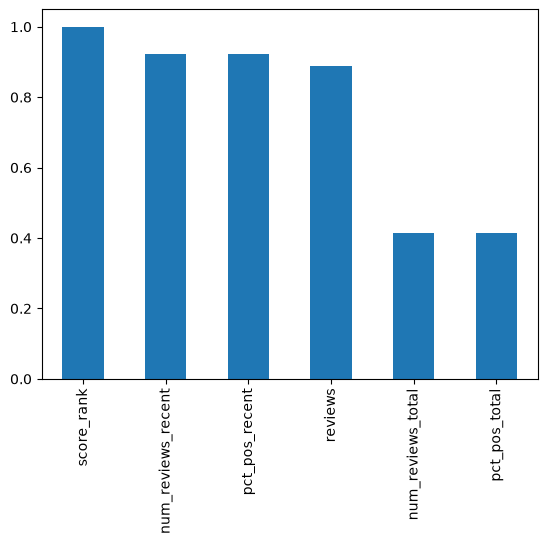

In [64]:
df.isnull().mean().sort_values(ascending=False)[0:6].plot(kind="bar")

# Target(y) Price değerlerinin incelenmesi

In [65]:
print("Data Type:", df["price"].dtype) #price sütunun veri tipi

Data Type: float64


In [66]:

print(df["price"].isna().sum()) #eksik değer sayısı

print(df["price"].describe())




0
count    98528.000000
mean         7.436772
std         13.425568
min          0.000000
25%          0.990000
50%          4.990000
75%          9.990000
max        999.980000
Name: price, dtype: float64


In [67]:
#Ücretsiz ve ücretli olan oyunların sayısı
print("Free Games:", (df["price"] == 0).sum())
print("Paid Games:", (df["price"] > 0).sum())

Free Games: 15311
Paid Games: 83217


Ücretsiz olan oyunları ayırıp. Sadece ücretli olanları ayrı bir df e aktardık.(df_paid)

In [68]:

df_paid = df[df["price"] > 0].copy()
print("Paid Games:", df_paid.shape)

print("Price Statistics:")
print(df_paid["price"].describe())


Paid Games: (83217, 36)
Price Statistics:
count    83217.000000
mean         8.805055
std         14.190192
min          0.490000
25%          2.990000
50%          4.990000
75%          9.990000
max        999.980000
Name: price, dtype: float64


# Outlier Detection

In [69]:

# Outlier Detection - IQR Method

Q1 = df_paid["price"].quantile(0.25)
Q3 = df_paid["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_paid[
    (df_paid["price"] < lower_bound) |
    (df_paid["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(outliers))


Q1: 2.99
Q3: 9.99
IQR: 7.0
Lower Bound: -7.51
Upper Bound: 20.490000000000002
Outlier Count: 4840


In [70]:


df_model = df_paid[df_paid["price"] <= 100].copy()

print("Original Paid Games:", len(df_paid))
print("Modeling Dataset:", len(df_model))
print("Excluded Games:", len(df_paid) - len(df_model))

print("\nPrice Statistics:")
print(df_model["price"].describe())


Original Paid Games: 83217
Modeling Dataset: 83010
Excluded Games: 207

Price Statistics:
count    83010.000000
mean         8.312991
std          8.866158
min          0.490000
25%          2.990000
50%          4.990000
75%          9.990000
max         99.990000
Name: price, dtype: float64


# Feature Engineering


release_year, language_count ve platform_count sütunları oluşturularak fiyat tahmininde kullanılacak yeni özellikler elde edilmektedir.

In [71]:

# Feature Engineering - Release Year

import pandas as pd

df_model["release_year"] = pd.to_datetime(
    df_model["release_date"].astype(str),
    errors="coerce"
).dt.year

print(df_model["release_year"].describe())

print("\nMissing Values:")
print(df_model["release_year"].isnull().sum())

display(df_model[["release_date", "release_year"]].head())


count    83010.000000
mean      2020.656608
std          3.204177
min       1997.000000
25%       2019.000000
50%       2021.000000
75%       2023.000000
max       2025.000000
Name: release_year, dtype: float64

Missing Values:
0


,release_date,release_year
305,2023-02-26,2023
306,2022-04-18,2022
307,2025-01-22,2025
308,2023-07-31,2023
309,2021-10-19,2021


In [72]:

import ast

# Count supported languages
def count_languages(value):
    try:
        languages = ast.literal_eval(value)
        return len(languages) if isinstance(languages, list) else 0
    except (ValueError, SyntaxError, TypeError):
        return 0

df_model["language_count"] = df_model["supported_languages"].apply(count_languages)

print(df_model["language_count"].describe())

print("\Missing Values:")
print(df_model["language_count"].isnull().sum())

display(df_model[["supported_languages", "language_count"]].head())


<>:15: SyntaxWarning: "\M" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\M"? A raw string is also an option.
<>:15: SyntaxWarning: "\M" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\M"? A raw string is also an option.
/var/folders/x3/sjg6nx3d4pg2vtqdm121y6y80000gn/T/ipykernel_20357/2193704746.py:15: SyntaxWarning: "\M" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\M"? A raw string is also an option.
  print("\Missing Values:")


count    83010.000000
mean         5.304216
std         13.159593
min          0.000000
25%          1.000000
50%          1.000000
75%          5.000000
max        103.000000
Name: language_count, dtype: float64
\Missing Values:
0


,supported_languages,language_count
305,['English'],1
306,"['English', 'Italian', 'Spanish - Spain']",3
307,"['English', 'Japanese', 'Simplified Chinese', ...",4
308,['English'],1
309,['Simplified Chinese'],1


In [73]:

# Feature Engineering - Platform Count

df_model["platform_count"] = (
    df_model[["windows", "mac", "linux"]]
    .astype(int)
    .sum(axis=1)
)

print(df_model["platform_count"].value_counts().sort_index())

print("\nMissing Values:")
print(df_model["platform_count"].isnull().sum())

display(
    df_model[
        ["windows", "mac", "linux", "platform_count"]
    ].head()
)


platform_count
1    64109
2    10304
3     8597
Name: count, dtype: int64

Missing Values:
0


,windows,mac,linux,platform_count
305,True,False,False,1
306,True,False,False,1
307,True,False,False,1
308,True,False,False,1
309,True,False,False,1


In [74]:
display(df_model[["name", "price"]].head())

display(df_model[["genres", "categories"]].head())

display(df_model[["release_year", "language_count"]].head())

,name,price
305,307 Racing,0.49
306,Fortress Building Puzzle,0.49
307,Investigating Alien Cats 调查外星猫,0.49
308,Lab Cat Escape,0.49
309,迅风的米斯特汀 Windy Mystletainn,0.49


,genres,categories
305,"['Racing', 'Simulation']","['Single-player', 'Family Sharing']"
306,"['Adventure', 'Casual', 'Indie', 'Simulation',...","['Single-player', 'Commentary available', 'Rem..."
307,['Indie'],"['Single-player', 'Steam Achievements', 'Famil..."
308,"['Action', 'Casual', 'Indie']","['Single-player', 'Steam Achievements', 'Famil..."
309,"['Adventure', 'RPG']","['Single-player', 'Steam Achievements', 'Steam..."


,release_year,language_count
305,2023,1
306,2022,3
307,2025,4
308,2023,1
309,2021,1


# X ve Y Feature Selection
Bağımsız değişkenlerin ve hedef değişkenin belirlenmesi

In [75]:

features = [
    "genres",
    "categories",
    "release_date",
    "required_age",
    "dlc_count",
    "achievements",
    "supported_languages",
    "windows",
    "mac",
    "linux"
]

X = df_model[features].copy()
y = df_model["price"]# Target Variable





In [76]:
print("X Eksik Değerler:")
print(X.isnull().sum())

print("\ny Eksik Değer Sayısı:", y.isnull().sum())

X Eksik Değerler:
genres                 0
categories             0
release_date           0
required_age           0
dlc_count              0
achievements           0
supported_languages    0
windows                0
mac                    0
linux                  0
dtype: int64

y Eksik Değer Sayısı: 0


Oluşturulan release_year, language_count ve platform_count sütunlarının eksik değerleri ve istatistiksel dağılımları kontrol edilmektedir.

In [77]:

# Check engineered features

new_features = [
    "release_year",
    "language_count",
    "platform_count"
]

print("Missing Values:")
print(df_model[new_features].isnull().sum())

print("\nSummary Statistics:")
display(df_model[new_features].describe())


Missing Values:
release_year      0
language_count    0
platform_count    0
dtype: int64

Summary Statistics:


,release_year,language_count,platform_count
count,83010.000000,83010.000000,83010.000000
mean,2020.656608,5.304216,1.331261
std,3.204177,13.159593,0.654724
min,1997.000000,0.000000,1.000000
25%,2019.000000,1.000000,1.000000
50%,2021.000000,1.000000,1.000000
75%,2023.000000,5.000000,1.000000
max,2025.000000,103.000000,3.000000


# String to List Conversion 
Data Preprocessing (Veri Ön İşleme)

genres ve categories sütunlarındaki metin biçimindeki listeler, Python liste formatına dönüştürülerek kategorik kodlama işlemine hazırlanmaktadır.

In [78]:

# Convert String to List

import ast

df_model["genres_list"] = df_model["genres"].apply(ast.literal_eval)

df_model["categories_list"] = df_model["categories"].apply(ast.literal_eval)

# Check Results
print(type(df_model["genres_list"].iloc[0]))
print(type(df_model["categories_list"].iloc[0]))

display(
    df_model[["genres_list", "categories_list"]].head()
)


<class 'list'>
<class 'list'>


,genres_list,categories_list
305,"[Racing, Simulation]","[Single-player, Family Sharing]"
306,"[Adventure, Casual, Indie, Simulation, Sports,...","[Single-player, Commentary available, Remote P..."
307,[Indie],"[Single-player, Steam Achievements, Family Sha..."
308,"[Action, Casual, Indie]","[Single-player, Steam Achievements, Family Sha..."
309,"[Adventure, RPG]","[Single-player, Steam Achievements, Steam Clou..."


# Missing Value Check (Eksik Değer Kontrolü)

Modele dahil edilen özelliklerde eksik değer olup olmadığı kontrol edilir. Eksik değer bulunması durumunda uygun veri doldurma yöntemleri uygulanabilir.

In [92]:
X.isnull().sum()

genres_list        0
categories_list    0
release_year       0
language_count     0
platform_count     0
required_age       0
dlc_count          0
achievements       0
windows            0
mac                0
linux              0
dtype: int64

Sayısal özelliklerde eksik değer tespit edilmediğinden SimpleImputer ile eksik veri doldurma işlemine ihtiyaç duyulmamıştır.

# Train-Test Split

Şimdi verilerimizi %80 eğitim, %20 test olarak ayıralım.

In [79]:

from sklearn.model_selection import train_test_split

# Feature Selection
features = [
    "genres_list",
    "categories_list",
    "release_year",
    "language_count",
    "platform_count",
    "required_age",
    "dlc_count",
    "achievements",
    "windows",
    "mac",
    "linux"
]

# X: Independent Variables
X = df_model[features].copy()

# y: Target Variable
y = df_model["price"].copy()

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (66408, 11)
X_test: (16602, 11)
y_train: (66408,)
y_test: (16602,)


# MultiLabelBinarizer (Çoklu Etiket Kodlama)

MultiLabelBinarizer, birden fazla kategori veya etiket içeren verileri makine öğrenmesi modellerinin kullanabileceği sayısal formata dönüştürür. Steam veri setimizde genres_list ve categories_list sütunlarını 0 ve 1 değerlerinden oluşan sütunlara dönüştürmek için kullanılmıştır.

OneHotEncoder: Her satırda tek bir kategori bulunduğunda kullanılır. Örneğin: Action.

MultiLabelBinarizer: Her satırda birden fazla kategori bulunduğunda kullanılır. Örneğin: ["Action", "Adventure", "Indie"].

In [ ]:

from sklearn.preprocessing import MultiLabelBinarizer
import pandas as pd

# Initialize encoder
genre_encoder = MultiLabelBinarizer()
train_genres = genre_encoder.fit_transform(X_train["genres_list"])# Fit and transform training data
test_genres = genre_encoder.transform(X_test["genres_list"])# Transform test data

# Convert to DataFrame
train_gen = pd.DataFrame(
    train_genres,
    columns=genre_encoder.classes_,
    index=X_train.index
).add_prefix("genre_")

test_gen = pd.DataFrame(
    test_genres,
    columns=genre_encoder.classes_,
    index=X_test.index
).add_prefix("genre_")

# Check results
print("Number of Genres:", len(genre_encoder.classes_))
print("Train Shape:", train_gen.shape)
print("Test Shape:", test_gen.shape)

display(train_gen.head())


Number of Genres: 34
Train Shape: (66408, 34)
Test Shape: (16602, 34)


,genre_360 Video,genre_Accounting,genre_Action,genre_Adventure,genre_Animation & Modeling,genre_Audio Production,genre_Casual,genre_Design & Illustration,genre_Documentary,genre_Early Access,...,genre_Short,genre_Simulation,genre_Software Training,genre_Sports,genre_Strategy,genre_Tutorial,genre_Utilities,genre_Video Production,genre_Violent,genre_Web Publishing
67969,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
70372,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
85790,0,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
80768,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
89354,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [90]:
new_features = ["release_year", "language_count", "platform_count"]

df_model[new_features].isnull().sum()

release_year      0
language_count    0
platform_count    0
dtype: int64

In [81]:

# Categories Encoding

category_encoder = MultiLabelBinarizer()

# Training data
train_categories = category_encoder.fit_transform(
    X_train["categories_list"]
)

# Test data
test_categories = category_encoder.transform(
    X_test["categories_list"]
)

# Convert to DataFrame
train_cat = pd.DataFrame(
    train_categories,
    columns=category_encoder.classes_,
    index=X_train.index
).add_prefix("category_")

test_cat = pd.DataFrame(
    test_categories,
    columns=category_encoder.classes_,
    index=X_test.index
).add_prefix("category_")

# Check results
print("Number of Categories:", len(category_encoder.classes_))
print("Train Shape:", train_cat.shape)
print("Test Shape:", test_cat.shape)

display(train_cat.head())


Number of Categories: 40
Train Shape: (66408, 40)
Test Shape: (16602, 40)


,category_Captions available,category_Co-op,category_Commentary available,category_Cross-Platform Multiplayer,category_Family Sharing,category_Full controller support,category_HDR available,category_In-App Purchases,category_Includes Source SDK,category_Includes level editor,...,category_Steam Timeline,category_Steam Trading Cards,category_Steam Turn Notifications,category_Steam Workshop,category_SteamVR Collectibles,category_Tracked Controller Support,category_VR Only,category_VR Support,category_VR Supported,category_Valve Anti-Cheat enabled
67969,0,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
70372,0,0,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
85790,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
80768,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
89354,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [82]:

# Combine Features

numeric_features = [
    "release_year",
    "language_count",
    "platform_count",
    "required_age",
    "dlc_count",
    "achievements",
    "windows",
    "mac",
    "linux"
]

# Training dataset
X_train_final = pd.concat([
    X_train[numeric_features].astype(float),
    train_gen,
    train_cat
], axis=1)

# Test dataset
X_test_final = pd.concat([
    X_test[numeric_features].astype(float),
    test_gen,
    test_cat
], axis=1)

# Check results
print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)

print("\nMissing Values:")
print(X_train_final.isnull().sum().sum())
print(X_test_final.isnull().sum().sum())

display(X_train_final.head())


X_train_final: (66408, 83)
X_test_final: (16602, 83)

Missing Values:
0
0


,release_year,language_count,platform_count,required_age,dlc_count,achievements,windows,mac,linux,genre_360 Video,...,category_Steam Timeline,category_Steam Trading Cards,category_Steam Turn Notifications,category_Steam Workshop,category_SteamVR Collectibles,category_Tracked Controller Support,category_VR Only,category_VR Support,category_VR Supported,category_Valve Anti-Cheat enabled
67969,2024.0,3.0,1.0,0.0,0.0,24.0,1.0,0.0,0.0,0,...,0,0,0,0,0,0,0,0,0,0
70372,2016.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0,...,0,1,0,0,0,0,0,0,0,0
85790,2023.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0,...,0,0,0,0,0,0,0,0,0,0
80768,2023.0,1.0,1.0,0.0,0.0,15.0,1.0,0.0,0.0,0,...,0,0,0,0,0,1,1,0,0,0
89354,2024.0,1.0,1.0,0.0,0.0,7.0,1.0,0.0,0.0,0,...,0,0,0,0,0,0,0,0,0,0


# Model Training - Linear Regression

In [83]:

# Model Training - Linear Regression

from sklearn.linear_model import LinearRegression

# Initialize model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train_final, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_final)



In [84]:

# Model Evaluation - Linear Regression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Display results
print(f"MAE: ${mae_lr:.2f}")
print(f"RMSE: ${rmse_lr:.2f}")
print(f"R²: {r2_lr:.4f}")


MAE: $5.13
RMSE: $7.81
R²: 0.2158


# Model Training - Random Forest

Random Forest algoritması kullanılarak birden fazla karar ağacının tahminleri birleştirilmekte ve oyun fiyatları tahmin edilmektedir. Modelin performansı MAE, RMSE ve R² metrikleriyle değerlendirilerek Linear Regression modeliyle karşılaştırılmaktadır.

In [85]:

# Model Training - Random Forest

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_final, y_train)
y_pred_rf = rf_model.predict(X_test_final)




In [94]:

# Model Training - Baseline

from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train_final, y_train)

y_pred_baseline = baseline_model.predict(X_test_final)


In [86]:



mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)
print(f"MAE: ${mae_rf:.2f}")
print(f"RMSE: ${rmse_rf:.2f}")
print(f"R²: {r2_rf:.4f}")


MAE: $4.56
RMSE: $7.08
R²: 0.3558


In [96]:

from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train_final, y_train)

y_pred_baseline = baseline_model.predict(X_test_final)


In [97]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_baseline = r2_score(y_test, y_pred_baseline)

print(f"MAE: ${mae_baseline:.2f}")
print(f"RMSE: ${rmse_baseline:.2f}")
print(f"R²: {r2_baseline:.4f}")


MAE: $5.94
RMSE: $8.82
R²: -0.0000


In [98]:

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print(f"MAE: ${mae_lr:.2f}")
print(f"RMSE: ${rmse_lr:.2f}")
print(f"R²: {r2_lr:.4f}")


MAE: $5.13
RMSE: $7.81
R²: 0.2158


In [99]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_final, y_train)

y_pred_rf = rf_model.predict(X_test_final)


In [100]:

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"MAE: ${mae_rf:.2f}")
print(f"RMSE: ${rmse_rf:.2f}")
print(f"R²: {r2_rf:.4f}")


MAE: $4.56
RMSE: $7.08
R²: 0.3558


In [101]:

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [mae_baseline, mae_lr, mae_rf],
    "RMSE": [rmse_baseline, rmse_lr, rmse_rf],
    "R²": [r2_baseline, r2_lr, r2_rf]
})

display(model_comparison.round(4))


,Model,MAE,RMSE,R²
0,Baseline,5.9386,8.8242,-0.0000
1,Linear Regression,5.1344,7.8140,0.2158
2,Random Forest,4.5621,7.0823,0.3558
